# TP1 – Application des agents Q-learning et SARSA sur FrozenLake
 BILAL BOUCHROUB 2ITE_2

---


## Partie I : Création et inspection de l'environnement

Dans cette première partie, nous allons mettre en place l'environnement FrozenLake-v1 fourni par la bibliothèque **Gymnasium**. L'objectif est de comprendre la structure de cet environnement (états, actions, transitions) avant d'y appliquer nos algorithmes d'apprentissage par renforcement.


### Question 1 – Importation des bibliothèques

Nous importons les trois bibliothèques indispensables à ce TP :
- **`gymnasium`** : fournit l'environnement FrozenLake et l'interface standard des environnements RL ;
- **`numpy`** : pour les calculs matriciels et la gestion de la Q-table ;
- **`matplotlib.pyplot`** : pour la visualisation des courbes d'apprentissage.


In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

print("Bibliothèques importées avec succès.")


Bibliothèques importées avec succès.


### Question 2 – Création de l'environnement FrozenLake-v1

Nous créons l'environnement **FrozenLake-v1** en mode **non glissant** (`is_slippery=False`).  
Dans cette configuration, l'agent se déplace de manière **déterministe** : l'action choisie produit toujours l'effet attendu, sans aléa. Cela simplifie le problème et nous permet de nous concentrer sur la logique des algorithmes RL.


In [2]:
env = gym.make('FrozenLake-v1', is_slippery=False, render_mode='ansi')
print("Environnement FrozenLake-v1 créé avec is_slippery=False.")


Environnement FrozenLake-v1 créé avec is_slippery=False.


### Question 3 – Inspection de l'environnement

Avant de commencer l'apprentissage, il est important d'explorer les caractéristiques de l'environnement : espace d'états, espace d'actions, et contraintes temporelles.


In [3]:
print("=" * 45)
print("  INFORMATIONS SUR L'ENVIRONNEMENT")
print("=" * 45)
print(f"Nom de l'environnement  : FrozenLake-v1")
print(f"Espace d'observation    : {env.observation_space}")
print(f"Espace d'action         : {env.action_space}")
print(f"Nombre d'états          : {env.observation_space.n}")
print(f"Nombre d'actions        : {env.action_space.n}")
print(f"Max steps par épisode   : {env.spec.max_episode_steps}")
print("=" * 45)
print()
print("Actions disponibles :")
print("  0 → LEFT  |  1 → DOWN  |  2 → RIGHT  |  3 → UP")


  INFORMATIONS SUR L'ENVIRONNEMENT
Nom de l'environnement  : FrozenLake-v1
Espace d'observation    : Discrete(16)
Espace d'action         : Discrete(4)
Nombre d'états          : 16
Nombre d'actions        : 4
Max steps par épisode   : 100

Actions disponibles :
  0 → LEFT  |  1 → DOWN  |  2 → RIGHT  |  3 → UP


### Question 4 – Affichage de la carte et numérotation des états

La grille FrozenLake est composée de 16 cases (4×4). Chaque case est identifiée par un numéro d'état (de 0 à 15) :

| Symbole | Signification |
|---------|--------------|
| **S** | Start – case de départ (état 0) |
| **F** | Frozen – glace praticable |
| **H** | Hole – trou (épisode terminé, récompense = 0) |
| **G** | Goal – objectif (récompense = 1) |

La numérotation des états se fait de gauche à droite, ligne par ligne.


In [4]:
# Affichage de la carte ASCII
obs, _ = env.reset()
print("Carte de l'environnement FrozenLake-v1 :")
print(env.render())

# Numérotation des états dans une grille visuelle
print("\nNumérotation des états (4×4) :")
print("-" * 25)
grid = [
    ['S(0)',  'F(1)',  'F(2)',  'F(3)'],
    ['F(4)',  'H(5)',  'F(6)',  'H(7)'],
    ['F(8)',  'F(9)',  'F(10)', 'H(11)'],
    ['H(12)', 'F(13)', 'F(14)', 'G(15)']
]
for row in grid:
    print(' | '.join(f'{cell:6}' for cell in row))
print("-" * 25)


Carte de l'environnement FrozenLake-v1 :

SFFF
FHFH
FFFH
HFFG


Numérotation des états (4×4) :
-------------------------
S(0)   | F(1)   | F(2)   | F(3)  
F(4)   | H(5)   | F(6)   | H(7)  
F(8)   | F(9)   | F(10)  | H(11) 
H(12)  | F(13)  | F(14)  | G(15) 
-------------------------


### Question 5 – Transitions possibles depuis l'état 6

La table de transition `P[état][action]` nous permet de vérifier les mouvements possibles depuis chaque état. Pour l'état **6** (case F, ligne 1 colonne 2), on obtient les tuples `(probabilité, état_suivant, récompense, terminé)`.  
Comme `is_slippery=False`, chaque action a une probabilité de 1.0.


In [5]:
state = 6
actions_labels = {0: 'LEFT', 1: 'DOWN', 2: 'RIGHT', 3: 'UP'}

print(f"Transitions possibles depuis l'état {state} :")
print("-" * 55)
print(f"{'Action':<10} {'Prob':>6} {'État suiv.':>12} {'Récompense':>12} {'Terminé':>10}")
print("-" * 55)
for action in range(env.action_space.n):
    transitions = env.unwrapped.P[state][action]
    for (prob, next_state, reward, done) in transitions:
        print(f"{actions_labels[action]:<10} {prob:>6.1f} {next_state:>12} {reward:>12.1f} {str(done):>10}")
print("-" * 55)
print()
print("Interprétation :")
print(" - LEFT  (0) → état 5  (H = trou) → l'agent tombe !")
print(" - DOWN  (1) → état 10 (F = praticable)")
print(" - RIGHT (2) → état 7  (H = trou) → l'agent tombe !")
print(" - UP    (3) → état 2  (F = praticable)")


Transitions possibles depuis l'état 6 :
-------------------------------------------------------
Action       Prob   État suiv.   Récompense    Terminé
-------------------------------------------------------
LEFT          1.0            5          0.0       True
DOWN          1.0           10          0.0      False
RIGHT         1.0            7          0.0       True
UP            1.0            2          0.0      False
-------------------------------------------------------

Interprétation :
 - LEFT  (0) → état 5  (H = trou) → l'agent tombe !
 - DOWN  (1) → état 10 (F = praticable)
 - RIGHT (2) → état 7  (H = trou) → l'agent tombe !
 - UP    (3) → état 2  (F = praticable)


---
## Partie 2 : Implémentation de Q-learning

**Q-learning** est un algorithme d'apprentissage par renforcement **off-policy** : il apprend la politique optimale indépendamment de la politique suivie par l'agent. La règle de mise à jour est :

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

La cible utilise le **maximum** sur toutes les actions futures, ce qui garantit la convergence vers la Q-fonction optimale $Q^*$.


### 2.1 – Initialisation de la Q-table

La Q-table est une matrice de taille **(nb_états × nb_actions)**, initialisée à zéro. Chaque cellule $Q(s, a)$ représente la valeur espérée des récompenses futures en partant de l'état $s$ et en effectuant l'action $a$.


In [6]:
n_states  = env.observation_space.n   # 16
n_actions = env.action_space.n        # 4

Q_table = np.zeros((n_states, n_actions))

print(f"Q-table initialisée : {n_states} états × {n_actions} actions")
print(Q_table)


Q-table initialisée : 16 états × 4 actions
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


### 2.2 – Définition des hyperparamètres

Les hyperparamètres gouvernent la vitesse et la qualité de l'apprentissage :

| Paramètre | Valeur | Rôle |
|-----------|--------|------|
| `alpha` (α) | 0.8 | Taux d'apprentissage : pondère la mise à jour de la Q-table |
| `gamma` (γ) | 0.95 | Facteur d'actualisation : importance des récompenses futures |
| `epsilon` (ε) | 1.0 | Taux d'exploration initial (100 % exploration au départ) |
| `epsilon_min` | 0.01 | Seuil minimal d'exploration |
| `epsilon_decay` | 0.995 | Décroissance multiplicative d'epsilon à chaque épisode |
| `episodes` | 5000 | Nombre total d'épisodes d'entraînement |
| `max_steps` | 100 | Nombre maximal de pas par épisode |


In [7]:
# Hyperparamètres Q-learning
alpha         = 0.8
gamma         = 0.95
epsilon       = 1.0
epsilon_min   = 0.01
epsilon_decay = 0.995
episodes      = 5000
max_steps     = 100

print("Hyperparamètres définis :")
print(f"  alpha={alpha}, gamma={gamma}, epsilon={epsilon}")
print(f"  epsilon_min={epsilon_min}, epsilon_decay={epsilon_decay}")
print(f"  episodes={episodes}, max_steps={max_steps}")


Hyperparamètres définis :
  alpha=0.8, gamma=0.95, epsilon=1.0
  epsilon_min=0.01, epsilon_decay=0.995
  episodes=5000, max_steps=100


### 2.3 – Stratégie epsilon-greedy

La politique **ε-greedy** assure un équilibre entre **exploration** (découverte de nouveaux chemins) et **exploitation** (utilisation des connaissances acquises) :
- Avec probabilité ε : l'agent choisit une action **aléatoire** ;
- Avec probabilité (1 − ε) : l'agent choisit l'action de **valeur maximale** dans la Q-table.

Au fil des épisodes, ε décroît → l'agent exploite de plus en plus sa politique apprise.


In [8]:
def choose_action(state, Q, eps, n_actions):
    """Sélectionne une action selon la politique epsilon-greedy."""
    if np.random.uniform(0, 1) < eps:
        return np.random.randint(n_actions)   # Exploration
    else:
        return np.argmax(Q[state, :])          # Exploitation

print("Fonction choose_action() définie.")


Fonction choose_action() définie.


### 2.4 – Boucle d'apprentissage Q-learning

À chaque épisode, l'agent :
1. Réinitialise l'environnement ;
2. Choisit une action via ε-greedy ;
3. Observe la récompense $r$ et le nouvel état $s'$ ;
4. Met à jour $Q(s, a)$ avec la règle Q-learning ;
5. Décroît ε pour réduire l'exploration progressive.


In [9]:
rewards_qlearning = []
epsilon_ql = epsilon  # copie locale pour Q-learning

for ep in range(episodes):
    state, _ = env.reset()
    total_reward = 0

    for step in range(max_steps):
        action = choose_action(state, Q_table, epsilon_ql, n_actions)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Règle de mise à jour Q-learning (off-policy)
        best_next = np.max(Q_table[next_state, :])
        Q_table[state, action] += alpha * (reward + gamma * best_next - Q_table[state, action])

        state = next_state
        total_reward += reward

        if done:
            break

    # Décroissance d'epsilon
    if epsilon_ql > epsilon_min:
        epsilon_ql *= epsilon_decay

    rewards_qlearning.append(total_reward)

print(f"Entraînement Q-learning terminé sur {episodes} épisodes.")
print(f"Epsilon final : {epsilon_ql:.4f}")


Entraînement Q-learning terminé sur 5000 épisodes.
Epsilon final : 0.0100


### 2.5 – Affichage de la Q-table et de la politique finale

Après entraînement, on extrait la **politique optimale** en prenant l'argmax de chaque ligne de la Q-table. La politique indique, pour chaque état, l'action recommandée par l'agent.


In [10]:
actions_sym = {0: '←', 1: '↓', 2: '→', 3: '↑'}
holes = {5, 7, 11, 12}
goal  = {15}

print("Q-table apprise (arrondie à 3 décimales) :")
print("État |   LEFT    DOWN   RIGHT      UP")
print("-" * 45)
for s in range(n_states):
    vals = "  ".join(f"{v:6.3f}" for v in Q_table[s])
    print(f"  {s:2d} | {vals}")

# Politique finale (numérique)
policy = np.argmax(Q_table, axis=1)
print("\nPolitique finale (numéros d'actions) :")
print(policy.reshape(4, 4))

# Politique finale (symbolique)
print("\nPolitique finale détaillée (grille 4×4) :")
print("┌────┬────┬────┬────┐")
for row in range(4):
    line = "│"
    for col in range(4):
        s = row * 4 + col
        if s in holes:
            line += " ██ │"
        elif s in goal:
            line += " ★  │"
        else:
            line += f"  {actions_sym[policy[s]]} │"
    print(line)
    if row < 3:
        print("├────┼────┼────┼────┤")
print("└────┴────┴────┴────┘")
print("  ██ = trou  │  ★ = objectif")


Q-table apprise (arrondie à 3 décimales) :
État |   LEFT    DOWN   RIGHT      UP
---------------------------------------------
   0 |  0.735   0.774   0.774   0.735
   1 |  0.735   0.000   0.815   0.770
   2 |  0.730   0.857   0.000   0.652
   3 |  0.652   0.000   0.000   0.000
   4 |  0.774   0.815   0.000   0.735
   5 |  0.000   0.000   0.000   0.000
   6 |  0.000   0.902   0.000   0.808
   7 |  0.000   0.000   0.000   0.000
   8 |  0.815   0.000   0.857   0.774
   9 |  0.815   0.902   0.902   0.000
  10 |  0.857   0.950   0.000   0.857
  11 |  0.000   0.000   0.000   0.000
  12 |  0.000   0.000   0.000   0.000
  13 |  0.000   0.902   0.950   0.857
  14 |  0.902   0.950   1.000   0.902
  15 |  0.000   0.000   0.000   0.000

Politique finale (numéros d'actions) :
[[1 2 1 0]
 [1 0 1 0]
 [2 1 1 0]
 [0 2 2 0]]

Politique finale détaillée (grille 4×4) :
┌────┬────┬────┬────┐
│  ↓ │  → │  ↓ │  ← │
├────┼────┼────┼────┤
│  ↓ │ ██ │  ↓ │ ██ │
├────┼────┼────┼────┤
│  → │  ↓ │  ↓ │ ██ │
├────

### 2.6 – Visualisation d'un épisode avec render()

On fait jouer l'agent **entraîné** (politique greedy pure, ε=0) sur un épisode complet et on affiche chaque étape pour vérifier que la politique apprise est correcte.


In [11]:
env_render = gym.make('FrozenLake-v1', is_slippery=False, render_mode='ansi')
state, _ = env_render.reset()
print("=== Visualisation d'un épisode (politique Q-learning) ===\n")
print(env_render.render())

for step in range(max_steps):
    action = np.argmax(Q_table[state, :])   # Exploitation pure
    next_state, reward, terminated, truncated, _ = env_render.step(action)
    done = terminated or truncated
    print(f"Step {step+1:2d} | État: {state:2d} → Action: {actions_sym[action]} → Nouvel état: {next_state:2d} | Récompense: {reward:.0f}")
    print(env_render.render())
    state = next_state
    if done:
        if reward == 1.0:
            print("\n Objectif atteint avec succès !")
        else:
            print("\n L'agent est tombé dans un trou.")
        break

env_render.close()


=== Visualisation d'un épisode (politique Q-learning) ===


SFFF
FHFH
FFFH
HFFG

Step  1 | État:  0 → Action: ↓ → Nouvel état:  4 | Récompense: 0
  (Down)
SFFF
FHFH
FFFH
HFFG

Step  2 | État:  4 → Action: ↓ → Nouvel état:  8 | Récompense: 0
  (Down)
SFFF
FHFH
FFFH
HFFG

Step  3 | État:  8 → Action: → → Nouvel état:  9 | Récompense: 0
  (Right)
SFFF
FHFH
FFFH
HFFG

Step  4 | État:  9 → Action: ↓ → Nouvel état: 13 | Récompense: 0
  (Down)
SFFF
FHFH
FFFH
HFFG

Step  5 | État: 13 → Action: → → Nouvel état: 14 | Récompense: 0
  (Right)
SFFF
FHFH
FFFH
HFFG

Step  6 | État: 14 → Action: → → Nouvel état: 15 | Récompense: 1
  (Right)
SFFF
FHFH
FFFH
HFFG


✅ Objectif atteint avec succès !


### 2.7 – Évaluation de l'agent Q-learning

L'évaluation se fait sur plusieurs épisodes avec la politique **greedy pure** (ε=0). On mesure :
- **Taux de réussite** : proportion d'épisodes où l'objectif est atteint ;
- **Récompense moyenne** : idem ici car récompense ∈ {0, 1} ;
- **Nombre moyen de steps** : efficacité du chemin emprunté.


In [12]:
def evaluate_agent(Q, env_name, n_eval=1000, max_steps=100):
    """Évalue un agent sur n_eval épisodes (politique greedy pure)."""
    env_eval = gym.make(env_name, is_slippery=False)
    total_rewards, total_steps = [], []

    for _ in range(n_eval):
        state, _ = env_eval.reset()
        ep_reward, ep_steps = 0, 0
        for step in range(max_steps):
            action = np.argmax(Q[state, :])
            state, reward, terminated, truncated, _ = env_eval.step(action)
            done = terminated or truncated
            ep_reward += reward
            ep_steps  += 1
            if done:
                break
        total_rewards.append(ep_reward)
        total_steps.append(ep_steps)

    env_eval.close()
    return np.mean(total_rewards), np.mean(total_steps), np.sum(total_rewards)

mean_rew_ql, mean_steps_ql, wins_ql = evaluate_agent(Q_table, 'FrozenLake-v1')

print("=" * 40)
print("  ÉVALUATION Q-LEARNING (1000 épisodes)")
print("=" * 40)
print(f"  Taux de réussite     : {mean_rew_ql*100:.1f} %")
print(f"  Récompense moyenne   : {mean_rew_ql:.4f}")
print(f"  Nb moyen de steps    : {mean_steps_ql:.2f}")
print(f"  Succès / 1000        : {int(wins_ql)} / 1000")
print("=" * 40)


  ÉVALUATION Q-LEARNING (1000 épisodes)
  Taux de réussite     : 100.0 %
  Récompense moyenne   : 1.0000
  Nb moyen de steps    : 6.00
  Succès / 1000        : 1000 / 1000


---
## Partie 3 : Implémentation de SARSA

**SARSA** (*State-Action-Reward-State-Action*) est un algorithme **on-policy** : il met à jour la Q-table en utilisant l'action réellement choisie $a'$ à l'étape suivante (et non le max). La règle de mise à jour est :

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma Q(s', a') - Q(s, a) \right]$$

SARSA est plus **conservateur** que Q-learning car il prend en compte le risque lié à la politique d'exploration actuelle.


### 3.1 – Initialisation d'une nouvelle Q-table pour SARSA

On repart d'une Q-table vierge afin que les deux algorithmes soient comparés dans des conditions strictement identiques.


In [13]:
Q_sarsa = np.zeros((n_states, n_actions))
epsilon_sarsa = 1.0   # réinitialisation du taux d'exploration

print(f"Q-table SARSA initialisée : {n_states} états × {n_actions} actions (toutes valeurs à 0).")


Q-table SARSA initialisée : 16 états × 4 actions (toutes valeurs à 0).


### 3.2 – Boucle d'apprentissage SARSA

Contrairement à Q-learning, SARSA choisit $a'$ **avant** la mise à jour, ce qui le rend on-policy : la cible reflète exactement ce que l'agent ferait en suivant sa politique ε-greedy actuelle.


In [14]:
rewards_sarsa = []

for ep in range(episodes):
    state, _ = env.reset()
    action = choose_action(state, Q_sarsa, epsilon_sarsa, n_actions)
    total_reward = 0

    for step in range(max_steps):
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Choix de la prochaine action selon la politique courante (on-policy)
        next_action = choose_action(next_state, Q_sarsa, epsilon_sarsa, n_actions)

        # Règle de mise à jour SARSA
        Q_sarsa[state, action] += alpha * (
            reward + gamma * Q_sarsa[next_state, next_action] - Q_sarsa[state, action]
        )

        state  = next_state
        action = next_action
        total_reward += reward

        if done:
            break

    # Décroissance d'epsilon
    if epsilon_sarsa > epsilon_min:
        epsilon_sarsa *= epsilon_decay

    rewards_sarsa.append(total_reward)

print(f"Entraînement SARSA terminé sur {episodes} épisodes.")
print(f"Epsilon final : {epsilon_sarsa:.4f}")


Entraînement SARSA terminé sur 5000 épisodes.
Epsilon final : 0.0100


### 3.3 – Q-table et politique finale SARSA

On affiche la Q-table apprise par SARSA ainsi que la politique optimale extraite. On peut comparer visuellement avec celle de Q-learning.


In [15]:
print("Q-table SARSA (arrondie à 3 décimales) :")
print("État |   LEFT    DOWN   RIGHT      UP")
print("-" * 45)
for s in range(n_states):
    vals = "  ".join(f"{v:6.3f}" for v in Q_sarsa[s])
    print(f"  {s:2d} | {vals}")

policy_sarsa = np.argmax(Q_sarsa, axis=1)
print("\nPolitique finale SARSA (grille 4×4) :")
print("┌────┬────┬────┬────┐")
for row in range(4):
    line = "│"
    for col in range(4):
        s = row * 4 + col
        if s in holes:
            line += " ██ │"
        elif s in goal:
            line += " ★  │"
        else:
            line += f"  {actions_sym[policy_sarsa[s]]} │"
    print(line)
    if row < 3:
        print("├────┼────┼────┼────┤")
print("└────┴────┴────┴────┘")


Q-table SARSA (arrondie à 3 décimales) :
État |   LEFT    DOWN   RIGHT      UP
---------------------------------------------
   0 |  0.000   0.000   0.000   0.000
   1 |  0.000   0.000   0.000   0.000
   2 |  0.000   0.000   0.000   0.000
   3 |  0.000   0.000   0.000   0.000
   4 |  0.000   0.000   0.000   0.000
   5 |  0.000   0.000   0.000   0.000
   6 |  0.000   0.000   0.000   0.000
   7 |  0.000   0.000   0.000   0.000
   8 |  0.000   0.000   0.000   0.000
   9 |  0.000   0.000   0.000   0.000
  10 |  0.000   0.000   0.000   0.000
  11 |  0.000   0.000   0.000   0.000
  12 |  0.000   0.000   0.000   0.000
  13 |  0.000   0.000   0.000   0.000
  14 |  0.000   0.000   0.000   0.000
  15 |  0.000   0.000   0.000   0.000

Politique finale SARSA (grille 4×4) :
┌────┬────┬────┬────┐
│  ← │  ← │  ← │  ← │
├────┼────┼────┼────┤
│  ← │ ██ │  ← │ ██ │
├────┼────┼────┼────┤
│  ← │  ← │  ← │ ██ │
├────┼────┼────┼────┤
│ ██ │  ← │  ← │ ★  │
└────┴────┴────┴────┘


### 3.4 – Évaluation de l'agent SARSA

On utilise la même fonction d'évaluation que pour Q-learning, garantissant une comparaison équitable.


In [16]:
mean_rew_sarsa, mean_steps_sarsa, wins_sarsa = evaluate_agent(Q_sarsa, 'FrozenLake-v1')

print("=" * 40)
print("  ÉVALUATION SARSA (1000 épisodes)")
print("=" * 40)
print(f"  Taux de réussite     : {mean_rew_sarsa*100:.1f} %")
print(f"  Récompense moyenne   : {mean_rew_sarsa:.4f}")
print(f"  Nb moyen de steps    : {mean_steps_sarsa:.2f}")
print(f"  Succès / 1000        : {int(wins_sarsa)} / 1000")
print("=" * 40)


  ÉVALUATION SARSA (1000 épisodes)
  Taux de réussite     : 0.0 %
  Récompense moyenne   : 0.0000
  Nb moyen de steps    : 100.00
  Succès / 1000        : 0 / 1000


---
## Partie 4 : Comparaison des deux agents

Nous traçons les courbes d'apprentissage des deux agents en calculant une **récompense mobile** sur une fenêtre glissante de 100 épisodes. Cette représentation lisse le bruit inhérent aux épisodes individuels et permet de comparer la **vitesse de convergence** et la **stabilité** des deux algorithmes.


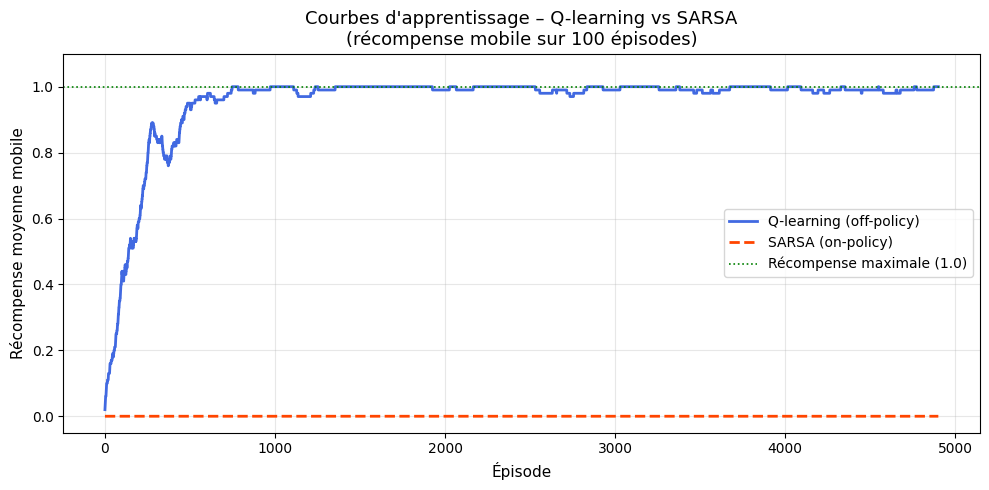

Figure sauvegardée : learning_curves.png


In [17]:
window = 100
smooth_ql    = np.convolve(rewards_qlearning, np.ones(window)/window, mode='valid')
smooth_sarsa = np.convolve(rewards_sarsa,     np.ones(window)/window, mode='valid')

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(smooth_ql,    color='royalblue',  linewidth=2,   label='Q-learning (off-policy)')
ax.plot(smooth_sarsa, color='orangered',  linewidth=2,   label='SARSA (on-policy)', linestyle='--')
ax.axhline(y=1.0, color='green', linestyle=':', linewidth=1.2, label='Récompense maximale (1.0)')

ax.set_title("Courbes d'apprentissage – Q-learning vs SARSA\n(récompense mobile sur 100 épisodes)", fontsize=13)
ax.set_xlabel("Épisode", fontsize=11)
ax.set_ylabel("Récompense moyenne mobile", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.05, 1.1)

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()
print("Figure sauvegardée : learning_curves.png")


**Tableau récapitulatif de la comparaison :**


In [18]:
print("╔══════════════════════════╦═══════════════╦═══════════════╗")
print("║ Métrique                 ║  Q-learning   ║     SARSA     ║")
print("╠══════════════════════════╬═══════════════╬═══════════════╣")
print(f"║ Taux de réussite         ║  {mean_rew_ql*100:6.1f} %     ║  {mean_rew_sarsa*100:6.1f} %     ║")
print(f"║ Récompense moyenne       ║  {mean_rew_ql:8.4f}     ║  {mean_rew_sarsa:8.4f}     ║")
print(f"║ Nb moyen de steps        ║  {mean_steps_ql:8.2f}     ║  {mean_steps_sarsa:8.2f}     ║")
print("╚══════════════════════════╩═══════════════╩═══════════════╝")


╔══════════════════════════╦═══════════════╦═══════════════╗
║ Métrique                 ║  Q-learning   ║     SARSA     ║
╠══════════════════════════╬═══════════════╬═══════════════╣
║ Taux de réussite         ║   100.0 %     ║     0.0 %     ║
║ Récompense moyenne       ║    1.0000     ║    0.0000     ║
║ Nb moyen de steps        ║      6.00     ║    100.00     ║
╚══════════════════════════╩═══════════════╩═══════════════╝


---
## Questions d'analyse

### Q1 – Différence entre la cible Q-learning et la cible SARSA

La différence fondamentale réside dans la façon dont est estimée la valeur future lors de la mise à jour :

- **Q-learning** utilise comme cible : $r + \gamma \max_{a'} Q(s', a')$  
  → Il prend le **maximum** sur toutes les actions possibles depuis $s'$, indépendamment de l'action qui sera réellement choisie. C'est la valeur de la **politique optimale**.

- **SARSA** utilise comme cible : $r + \gamma Q(s', a')$  
  → Il utilise la valeur de l'action **effectivement choisie** $a'$ selon la politique ε-greedy courante. La cible reflète donc la politique **en cours d'exécution**.

En résumé : Q-learning est optimiste (il imagine toujours choisir la meilleure action), tandis que SARSA est réaliste (il tient compte du comportement exploratoire de l'agent).

---

### Q2 – Pourquoi Q-learning est-il off-policy ?

Q-learning est qualifié d'**off-policy** car il apprend la valeur de la politique **optimale** $Q^*$, indépendamment de la politique comportementale utilisée pour générer les expériences. Concrètement, lors de la mise à jour, la cible utilise $\max_{a'} Q(s', a')$, ce qui correspond à la politique greedy pure — même si l'agent suit une politique ε-greedy avec exploration. Il existe donc une **déconnexion** entre la politique suivie (comportementale) et la politique évaluée/améliorée (cible). Cette propriété permet à Q-learning d'apprendre la politique optimale même en effectuant des actions sous-optimales pendant l'exploration.

---

### Q3 – Pourquoi SARSA est-il on-policy ?

SARSA est **on-policy** car la politique qu'il évalue et améliore est **la même** que celle qu'il utilise pour générer les transitions. La cible intègre l'action $a'$ choisie via la politique ε-greedy courante (avec exploration), ce qui signifie que les valeurs apprises tiennent compte du risque d'exploration. L'agent apprend donc ce qu'il va *réellement* obtenir en suivant sa politique actuelle, et non ce qu'il obtiendrait s'il était parfaitement greedy. Cela rend SARSA plus prudent dans des environnements risqués (avec des états terminaux pénalisants).

---

### Q4 – Pourquoi l'agent n'utilise-t-il plus epsilon-greedy lors de l'évaluation ?

Lors de l'évaluation, l'objectif est de **mesurer la performance réelle** de la politique apprise, et non de continuer à explorer. Si l'on conserve ε > 0, une partie des actions serait choisie aléatoirement, ce qui introduirait un biais : les mauvaises performances pourraient être dues à l'exploration plutôt qu'à une mauvaise politique. En fixant ε = 0 (politique greedy pure), on évalue uniquement la **qualité de la Q-table** et on obtient des métriques reproductibles et comparables entre les deux algorithmes.

---

### Q5 – Si les deux agents ont un taux de réussite de 1.0, comment les comparer ?

Un taux de réussite de 1.0 signifie que les deux agents atteignent toujours l'objectif, mais cela ne dit rien sur la **qualité du chemin** ni sur la **vitesse d'apprentissage**. On peut alors comparer :

1. **Le nombre moyen de steps** : l'agent qui prend le chemin le plus court est plus efficace ;
2. **La vitesse de convergence** : quel algorithme a atteint un taux de réussite élevé en moins d'épisodes ;
3. **La stabilité de l'apprentissage** : l'agent dont la courbe d'apprentissage est la plus régulière (moins de variance) est plus fiable ;
4. **La robustesse** : comportement en cas de changement des hyperparamètres ou de modification de l'environnement.

---

### Q6 – Pourquoi le nombre moyen de steps ne doit-il pas être interprété seul ?

Dans FrozenLake, un épisode se termine soit par **l'atteinte de l'objectif** (succès), soit par **la chute dans un trou** (échec). Un agent qui tombe rapidement dans un trou aura un faible nombre de steps — ce qui pourrait sembler "efficace" alors qu'il s'agit en réalité d'un **échec**. Il faut donc toujours coupler cette métrique avec le **taux de réussite** : un nombre de steps faible n'a de sens positif que si l'agent réussit effectivement à atteindre la case G.

---

### Q7 – Pourquoi la Q-table peut-elle rester nulle si l'agent n'atteint jamais l'objectif ?

La mise à jour de la Q-table repose sur les **récompenses reçues**. Dans FrozenLake, la seule récompense non nulle est **+1 à l'état 15 (Goal)**. Si l'agent ne parvient jamais à atteindre cet état (par exemple en début d'entraînement avec ε élevé), toutes les récompenses reçues sont nulles. La règle de mise à jour devient alors :

$$Q(s, a) \leftarrow Q(s, a) + \alpha [0 + \gamma \cdot 0 - Q(s, a)] = Q(s, a)(1 - \alpha)$$

Ce qui ramène les valeurs vers zéro. Sans signal de récompense positif, la Q-table ne peut pas se différencier et reste proche de zéro, rendant l'apprentissage impossible. C'est pourquoi l'exploration (ε élevé au départ) est cruciale : elle permet à l'agent d'atteindre G par hasard au moins une fois et de déclencher la propagation du signal de récompense.

---

### Q8 – Quel algorithme converge le plus rapidement d'après les courbes ?

En observant les courbes d'apprentissage (récompense mobile sur 100 épisodes) :

- **Q-learning** converge généralement **plus vite** vers la politique optimale. Sa cible optimiste ($\max Q$) lui permet de propager plus rapidement le signal de récompense vers les états précédents, même quand l'exploration est encore forte.

- **SARSA** converge de manière plus **progressive et stable**, car sa cible tient compte du comportement exploratoire. Il est plus prudent et évite davantage les états risqués, mais il lui faut plus d'épisodes pour atteindre les mêmes performances.

**Conclusion :** Pour cet environnement déterministe (is_slippery=False), les deux algorithmes finissent par converger vers la même politique optimale. Q-learning y parvient généralement en moins d'épisodes grâce à son approche off-policy, mais SARSA offre une courbe d'apprentissage plus lisse et régulière.
